In [1]:
import copy, math
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=2)

In [2]:
X_train = np.array([[2104, 5, 1, 45], [1416, 3, 2, 40], [852, 2, 1, 35]])
y_train = np.array([460, 232, 178])

In [3]:
def predict_output_loop(x, w, b):
    n = x.shape[0]
    f_wb = 0
    for i in range(n):
        f_wb += x[i] * w[i]
    f_wb += b
    return f_wb

In [4]:
def predict_output_dot(x, w, b):
    f_wb = np.dot(x, w) + b
    return f_wb

In [5]:
def compute_cost(X, y, w, b):
    m = X.shape[0]
    cost_sum = 0
    for i in range(m):
        f_wb = np.dot(X[i], w) + b
        cost = (f_wb - y[i]) ** 2
        cost_sum += cost
    total_cost = cost_sum / (2*m)
    return total_cost

In [6]:
def compute_gradient(X, y, w, b):
    m, n = X.shape
    dj_dw = np.zeros(n)
    dj_db = 0
    for i in range(m):
        err = (np.dot(X[i], w) + b) - y[i]
        for j in range(n):
            dj_dw[j] += err * X[i][j]
        dj_db += err
    dj_dw /= m
    dj_db /= m
    return dj_dw, dj_db

In [7]:
def gradient_descent(X, y, w_in, b_in, alpha, num_iters, compute_cost, compute_gradient):
    J_history = []
    w = w_in
    b = b_in
    for i in range(num_iters):
        dj_dw, dj_db = compute_gradient(X, y, w, b)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        if i < 100000:
            J_history.append(compute_cost(X, y, w, b))

        if i % math.ceil(num_iters/10) == 0:
            print(
                f"Iteration {i:4}: Cost: {J_history[-1]:.4e}",
                f"w: {w}, b: {b: .4e}"
            )
    return w, b, J_history

In [8]:
w_init = np.zeros(X_train.shape[1])
b_init = 0
alpha = 0.0000005
iterations = 10000
w_final, b_final, cost_hist = gradient_descent(X_train, y_train, w_init, b_init, alpha, iterations, compute_cost, compute_gradient)

print(f"\nw, b found by gradient descent: {w_final}, {b_final}")

Iteration    0: Cost: 2.5295e+03 w: [2.41e-01 5.59e-04 1.84e-04 6.03e-03], b:  1.4500e-04
Iteration 1000: Cost: 6.8669e+02 w: [ 0.2   0.   -0.01 -0.07], b: -2.2377e-03
Iteration 2000: Cost: 6.7719e+02 w: [ 0.21  0.01 -0.02 -0.13], b: -4.4872e-03
Iteration 3000: Cost: 6.6848e+02 w: [ 0.21  0.01 -0.03 -0.2 ], b: -6.6323e-03
Iteration 4000: Cost: 6.6050e+02 w: [ 0.21  0.01 -0.04 -0.26], b: -8.6773e-03
Iteration 5000: Cost: 6.5319e+02 w: [ 0.21  0.02 -0.06 -0.32], b: -1.0627e-02
Iteration 6000: Cost: 6.4649e+02 w: [ 0.21  0.02 -0.07 -0.38], b: -1.2485e-02
Iteration 7000: Cost: 6.4035e+02 w: [ 0.21  0.02 -0.08 -0.43], b: -1.4255e-02
Iteration 8000: Cost: 6.3472e+02 w: [ 0.21  0.03 -0.09 -0.48], b: -1.5942e-02
Iteration 9000: Cost: 6.2956e+02 w: [ 0.22  0.03 -0.1  -0.53], b: -1.7549e-02

w, b found by gradient descent: [ 0.22  0.03 -0.11 -0.58], -0.019077710470483206


In [9]:
x = np.arange(1,10001)
y = cost_hist
print(len(x), len(y))

10000 10000


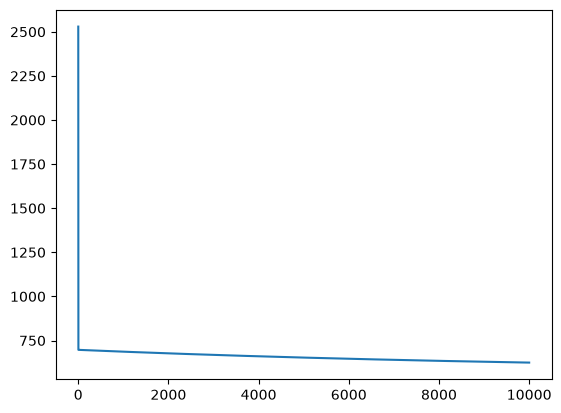

In [10]:
plt.plot(x,y)